In [1]:
%load_ext autoreload
%autoreload 3

# compression evaluation

In [2]:
import cartopy.crs as ccrs
import healpix_geo
import healpix_plot
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import xdggs  # noqa: F401
import zarr
import s3fs
import fsspec
import os

os.environ["ZARR_V3_EXPERIMENTAL_API"] = "1"  #

import hcc  # noqa: F401
import hcc.codecs.dct
import hcc.codecs.grad_dct

## flattening debugging

## Generate S2 data

In [3]:
storage_options = dict(
    key="3f066a359ca347eba4d61d0f8c7a52e6",
    secret="3b7545ac55e14c9abb0d9355f8a98f8c",
    client_kwargs={"endpoint_url": "https://s3.gra.io.cloud.ovh.net"},
)

fs = fsspec.filesystem("s3", **storage_options)

mapper = fs.get_mapper(
    "s3://grid4earth/jmtest/s2_multi_chunk_healpix.zarr"
)

dt = xr.open_datatree(
    mapper,
    engine="zarr",
    consolidated=True,
    chunks={}
)

/srv/conda/envs/notebook/lib/python3.12/site-packages/zarr/codecs/numcodecs/_codecs.py:141: ZarrUserWarning: Numcodecs codecs are not in the Zarr version 3 specification and may not be supported by other zarr implementations.
  super().__init__(**codec_config)


In [4]:
dt.measurements.reflectance['20']

<xarray.DataTree '20'>
Group: /measurements/reflectance/20
    Dimensions:  (cells: 13194139533312)
    Dimensions without coordinates: cells
    Data variables:
        b02      (cells) float64 106TB dask.array<chunksize=(1048576,), meta=np.ndarray>
        b03      (cells) float64 106TB dask.array<chunksize=(1048576,), meta=np.ndarray>
        b04      (cells) float64 106TB dask.array<chunksize=(1048576,), meta=np.ndarray>
        b08      (cells) float64 106TB dask.array<chunksize=(1048576,), meta=np.ndarray>

In [5]:
from healpix_geo import nested

level=20
if level==17:
    lon_min=0
    lon_max=1
    lat_min=49
    lat_max=50
    fov_deg=4.0
    band='b09'

if level==20:
    lon_min=2.03
    lon_max=2.07
    lat_min=48.600
    lat_max=48.630
#    fov_deg=0.05
    band='b02'
#    lon_min=2.333333-0.01/np.cos(np.deg2rad(48.866667))
#    lon_max=2.333333+0.01/np.cos(np.deg2rad(48.866667))
#    lat_min=48.866667-0.01
#    lat_max=48.866667+0.01
#    fov_deg=0.02
    band='b02'

ds=dt.measurements.reflectance[f'{level}']

print(level)
nside = 2**level
nest = True

# 4 coins de la bbox (lon/lat en degrés)
bbox= (lon_min,lat_min,lon_max,lat_max)

cell_ids,_,_ = nested.zone_coverage(bbox, level, ellipsoid='WGS84', flat=True)

da = ds[band]

# cell_ids : array d'IDs HEALPix NESTED de ta bbox (par ex query_polygon)
sub = da.isel(cells=cell_ids).compute()
sub.values.shape,np.nanstd(sub.values)
cell_ids

20


array([749957240831, 749957241855, 749957242111, ..., 749958234636,
       749958234640, 749958234656], shape=(255898,), dtype=uint64)

In [6]:
parent_level = 9
parent_ids = healpix_geo.nested.zoom_to(
    cell_ids,
    depth=level,
    new_depth=parent_level,
)
parent_ids, counts = np.unique(parent_ids, return_counts=True)


In [7]:
chunk_level=10
child_ids = healpix_geo.nested.zoom_to(
    parent_ids,
    depth=parent_level,
    new_depth=level,
)
#parent_ids, counts = np.unique(parent_ids, return_counts=True)
child_ids =np.unique(child_ids, return_counts=False)
child_ids

chunk=4**(level-chunk_level)
ds=dt.measurements.reflectance[f'{level}'].to_dataset().isel(cells=child_ids).assign_coords(cell_ids=("cells", child_ids))
display(ds)
ds.chunk({'cells': chunk}).to_zarr('toto.zarr', mode="w")

<xarray.Dataset> Size: 168MB
Dimensions:   (cells: 4194304)
Coordinates:
    cell_ids  (cells) uint64 34MB 749954138112 749954138113 ... 749958332415
Dimensions without coordinates: cells
Data variables:
    b02       (cells) float64 34MB dask.array<chunksize=(1048576,), meta=np.ndarray>
    b03       (cells) float64 34MB dask.array<chunksize=(1048576,), meta=np.ndarray>
    b04       (cells) float64 34MB dask.array<chunksize=(1048576,), meta=np.ndarray>
    b08       (cells) float64 34MB dask.array<chunksize=(1048576,), meta=np.ndarray>

/srv/conda/envs/notebook/lib/python3.12/site-packages/zarr/codecs/numcodecs/_codecs.py:141: ZarrUserWarning: Numcodecs codecs are not in the Zarr version 3 specification and may not be supported by other zarr implementations.
  super().__init__(**codec_config)
/srv/conda/envs/notebook/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [9]:
import xarray as xr

ds = xr.open_zarr("toto.zarr").dggs.decode(
    {
        "grid_name": "healpix",
        "level": level,
        "indexing_scheme": "nested",
        "ellipsoid": "sphere",
    }
)

ds

<xarray.Dataset> Size: 168MB
Dimensions:   (cells: 4194304)
Coordinates:
  * cell_ids  (cells) uint64 34MB 749954138112 749954138113 ... 749958332415
Dimensions without coordinates: cells
Data variables:
    b02       (cells) float64 34MB dask.array<chunksize=(1048576,), meta=np.ndarray>
    b03       (cells) float64 34MB dask.array<chunksize=(1048576,), meta=np.ndarray>
    b04       (cells) float64 34MB dask.array<chunksize=(1048576,), meta=np.ndarray>
    b08       (cells) float64 34MB dask.array<chunksize=(1048576,), meta=np.ndarray>
Indexes:
    cell_ids  HealpixIndex(level=20, indexing_scheme=nested, kind=pandas)

## roundtrip with the DCT codec

In [10]:
dct_store = zarr.storage.MemoryStore()
encoding = {
    name: {
        "serializer": hcc.codecs.dct.HccDctCodec(delta=1, top_k=14000),
    }
    for name in ds.data_vars
}
ds.dggs.encode(convention="zarr").to_zarr(
    dct_store,
    mode="w",
    encoding=encoding,
    consolidated=False,
)

In [11]:
grad_dct_store = zarr.storage.MemoryStore()
encoding = {
    name: {
        "serializer": hcc.codecs.grad_dct.HccGradDctCodec(window=8),
    }
    for name in ds.data_vars
}
ds.dggs.encode(convention="zarr").to_zarr(
    grad_dct_store,
    mode="w",
    encoding=encoding,
    consolidated=False,
)

In [12]:
uncompressed_store = zarr.storage.MemoryStore()
ds.dggs.encode(convention="zarr").to_zarr(
    uncompressed_store,
    mode="w",
    consolidated=False,
)

## simple evaluation

In [13]:
def count_objects(store):
    return len(
        [
            name
            for name in store._store_dict
            if not name.startswith("cell_ids/") and "zarr.json" not in name
        ]
    )


{
    "uncompressed": count_objects(uncompressed_store),
    "dct": count_objects(dct_store),
    "grad_dct": count_objects(grad_dct_store),
}

{'uncompressed': 16, 'dct': 16, 'grad_dct': 16}

In [14]:
def store_size(store):
    sizes = {
        key: value.as_array_like().nbytes for key, value in store._store_dict.items()
    }

    return sum(sizes.values())


{
    "uncompressed": store_size(uncompressed_store) / 1e6,
    "dct": store_size(dct_store) / 1e6,
    "grad_dct": store_size(grad_dct_store) / 1e6,
}

{'uncompressed': 129.32019, 'dct': 36.66107, 'grad_dct': 33.722594}

In [15]:
print(grad_dct_store._store_dict["b04/zarr.json"].to_bytes().decode())

{
  "shape": [
    4194304
  ],
  "data_type": "float64",
  "chunk_grid": {
    "name": "regular",
    "configuration": {
      "chunk_shape": [
        1048576
      ]
    }
  },
  "chunk_key_encoding": {
    "name": "default",
    "configuration": {
      "separator": "/"
    }
  },
  "fill_value": "NaN",
  "codecs": [
    {
      "name": "hcc-grad-dct",
      "configuration": {
        "window": 8
      }
    },
    {
      "name": "zstd",
      "configuration": {
        "level": 0,
        "checksum": false
      }
    }
  ],
  "attributes": {
    "_ARRAY_DIMENSIONS": [
      "cells"
    ],
    "dimension_names": [
      "cells"
    ],
    "coordinates": "cell_ids",
    "_FillValue": "AAAAAAAA+H8="
  },
  "dimension_names": [
    "cells"
  ],
  "zarr_format": 3,
  "node_type": "array",
  "storage_transformers": []
}


In [16]:
print(dct_store._store_dict["b04/zarr.json"].to_bytes().decode())

{
  "shape": [
    4194304
  ],
  "data_type": "float64",
  "chunk_grid": {
    "name": "regular",
    "configuration": {
      "chunk_shape": [
        1048576
      ]
    }
  },
  "chunk_key_encoding": {
    "name": "default",
    "configuration": {
      "separator": "/"
    }
  },
  "fill_value": "NaN",
  "codecs": [
    {
      "name": "hcc-dct",
      "configuration": {
        "delta": 1,
        "top_k": 14000,
        "quantization_dtype": "int16"
      }
    },
    {
      "name": "zstd",
      "configuration": {
        "level": 0,
        "checksum": false
      }
    }
  ],
  "attributes": {
    "_ARRAY_DIMENSIONS": [
      "cells"
    ],
    "dimension_names": [
      "cells"
    ],
    "coordinates": "cell_ids",
    "_FillValue": "AAAAAAAA+H8="
  },
  "dimension_names": [
    "cells"
  ],
  "zarr_format": 3,
  "node_type": "array",
  "storage_transformers": []
}


## value comparison

In [17]:
reopened_dct = (
    xr.open_dataset(dct_store, engine="zarr", consolidated=False)
    .dggs.decode(convention="zarr")
    .load()
)
reopened_grad_dct = (
    xr.open_dataset(grad_dct_store, engine="zarr", consolidated=False)
    .dggs.decode(convention="zarr")
    .load()
)

reopened_grad_dct

<xarray.Dataset> Size: 168MB
Dimensions:   (cells: 4194304)
Coordinates:
  * cell_ids  (cells) uint64 34MB 749954138112 749954138113 ... 749958332415
Dimensions without coordinates: cells
Data variables:
    b02       (cells) float64 34MB 0.09606 0.09537 0.09027 ... 0.1028 0.09828
    b03       (cells) float64 34MB 0.1066 0.1045 0.08531 ... 0.1025 0.09581
    b08       (cells) float64 34MB 0.2881 0.2942 0.3427 ... 0.4632 0.4546 0.4586
    b04       (cells) float64 34MB 0.08502 0.08193 0.06812 ... 0.07892 0.076
Indexes:
    cell_ids  HealpixIndex(level=20, indexing_scheme=nested, kind=pandas)

In [18]:
level = reopened_dct.dggs.grid_info.level

healpix_grid = healpix_plot.HealpixGrid(
    level=level, indexing_scheme="nested", ellipsoid="WGS84"
)

cell_ids = reopened_dct["cell_ids"].values
data_dct = reopened_dct["b04"].data

data_grad_dct = reopened_grad_dct["b04"].data

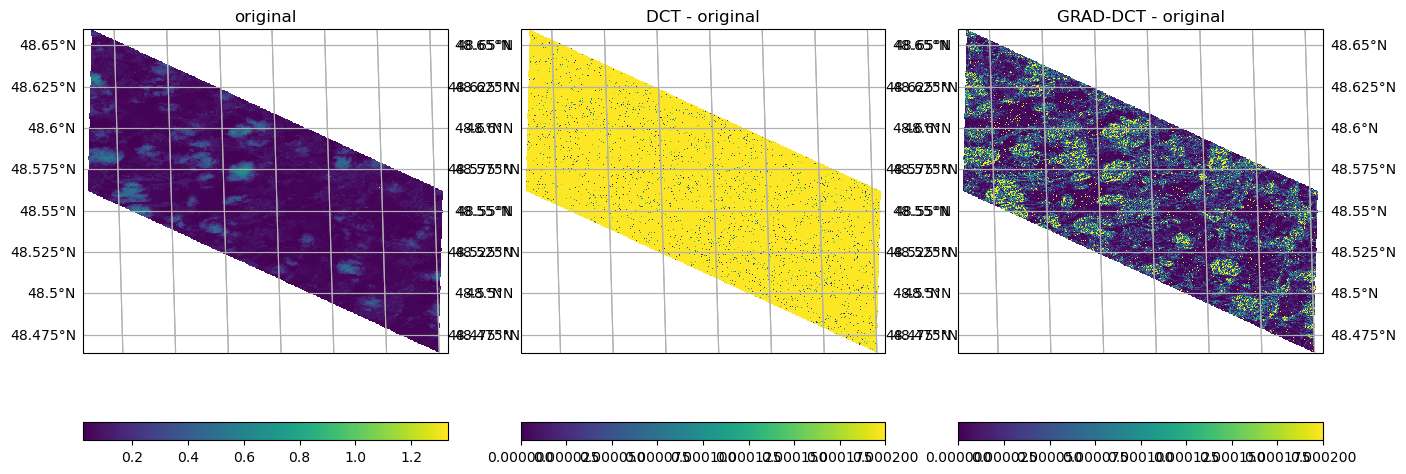

In [19]:
fig, axes = plt.subplots(
    1, 3, subplot_kw={"projection": ccrs.Mollweide()}, figsize=(16, 6)
)

mappable = healpix_plot.plot(
    cell_ids,
    ds["b04"].values,
    healpix_grid=healpix_grid,
    sampling_grid={"shape": 512},
    ax=axes[0],
)
axes[0].set_title("original")
fig.colorbar(mappable, orientation="horizontal")

axes[0].coastlines()
axes[0].gridlines(draw_labels="x")
axes[0].gridlines(draw_labels="y")


mappable = healpix_plot.plot(
    cell_ids,
    abs(data_dct - ds["b04"].values),
    healpix_grid=healpix_grid,
    sampling_grid={"shape": 512},
    ax=axes[1],
    cmap="viridis",
    vmin=0,
    vmax=0.0002,
)
axes[1].set_title("DCT - original")
fig.colorbar(mappable, orientation="horizontal")

axes[1].coastlines()
axes[1].gridlines(draw_labels="x")
axes[1].gridlines(draw_labels="y")

mappable = healpix_plot.plot(
    cell_ids,
    abs(data_grad_dct - ds["b04"].values),
    healpix_grid=healpix_grid,
    sampling_grid={"shape": 512},
    ax=axes[2],
    cmap="viridis",
    vmin=0,
    vmax=0.0002,
)
axes[2].set_title("GRAD-DCT - original")
fig.colorbar(mappable, orientation="horizontal")

axes[2].coastlines()
axes[2].gridlines(draw_labels="x")
axes[2].gridlines(draw_labels="y")

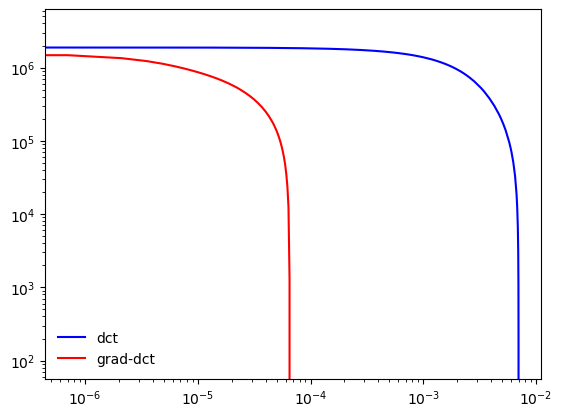

In [20]:
hy, hx = np.histogram(data_dct - ds["b04"].values, bins=10000, range=[-7e-3, 7e-3])
hy2, hx = np.histogram(data_grad_dct - ds["b04"].values, bins=10000, range=[-7e-3, 7e-3])

l1 = "dct"
l2 = "grad-dct"

plt.plot((hx[1:] + hx[:-1]) / 2, np.sum(hy) - np.cumsum(abs(hy)), color="b", label=l1)
plt.plot((hx[1:] + hx[:-1]) / 2, np.sum(hy) - np.cumsum(abs(hy2)), color="r", label=l2)
plt.yscale("log")
plt.xscale("log")
plt.legend(frameon=0)

## PowerSpectrum